In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
data = pd.read_csv('cancer patient data sets.csv')
data.head()

,index,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,0,P1,33,1,2,4,5,4,3,2,...,3,4,2,2,3,1,2,3,4,Low
1,1,P10,17,1,3,1,5,3,4,2,...,1,3,7,8,6,2,1,7,2,Medium
2,2,P100,35,1,4,5,6,5,5,4,...,8,7,9,2,1,4,6,7,2,High
3,3,P1000,37,1,7,7,7,7,6,7,...,4,2,3,1,4,5,6,7,5,High
4,4,P101,46,1,6,8,7,7,7,6,...,3,2,4,1,4,2,4,2,3,High


In [54]:
df_feature = data.copy()
df_feature = df_feature.drop(['index', 'Patient Id'], axis = 1)
df_feature.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1000 non-null   int64 
 1   Gender                    1000 non-null   int64 
 2   Air Pollution             1000 non-null   int64 
 3   Alcohol use               1000 non-null   int64 
 4   Dust Allergy              1000 non-null   int64 
 5   OccuPational Hazards      1000 non-null   int64 
 6   Genetic Risk              1000 non-null   int64 
 7   chronic Lung Disease      1000 non-null   int64 
 8   Balanced Diet             1000 non-null   int64 
 9   Obesity                   1000 non-null   int64 
 10  Smoking                   1000 non-null   int64 
 11  Passive Smoker            1000 non-null   int64 
 12  Chest Pain                1000 non-null   int64 
 13  Coughing of Blood         1000 non-null   int64 
 14  Fatigue                  

## EDA

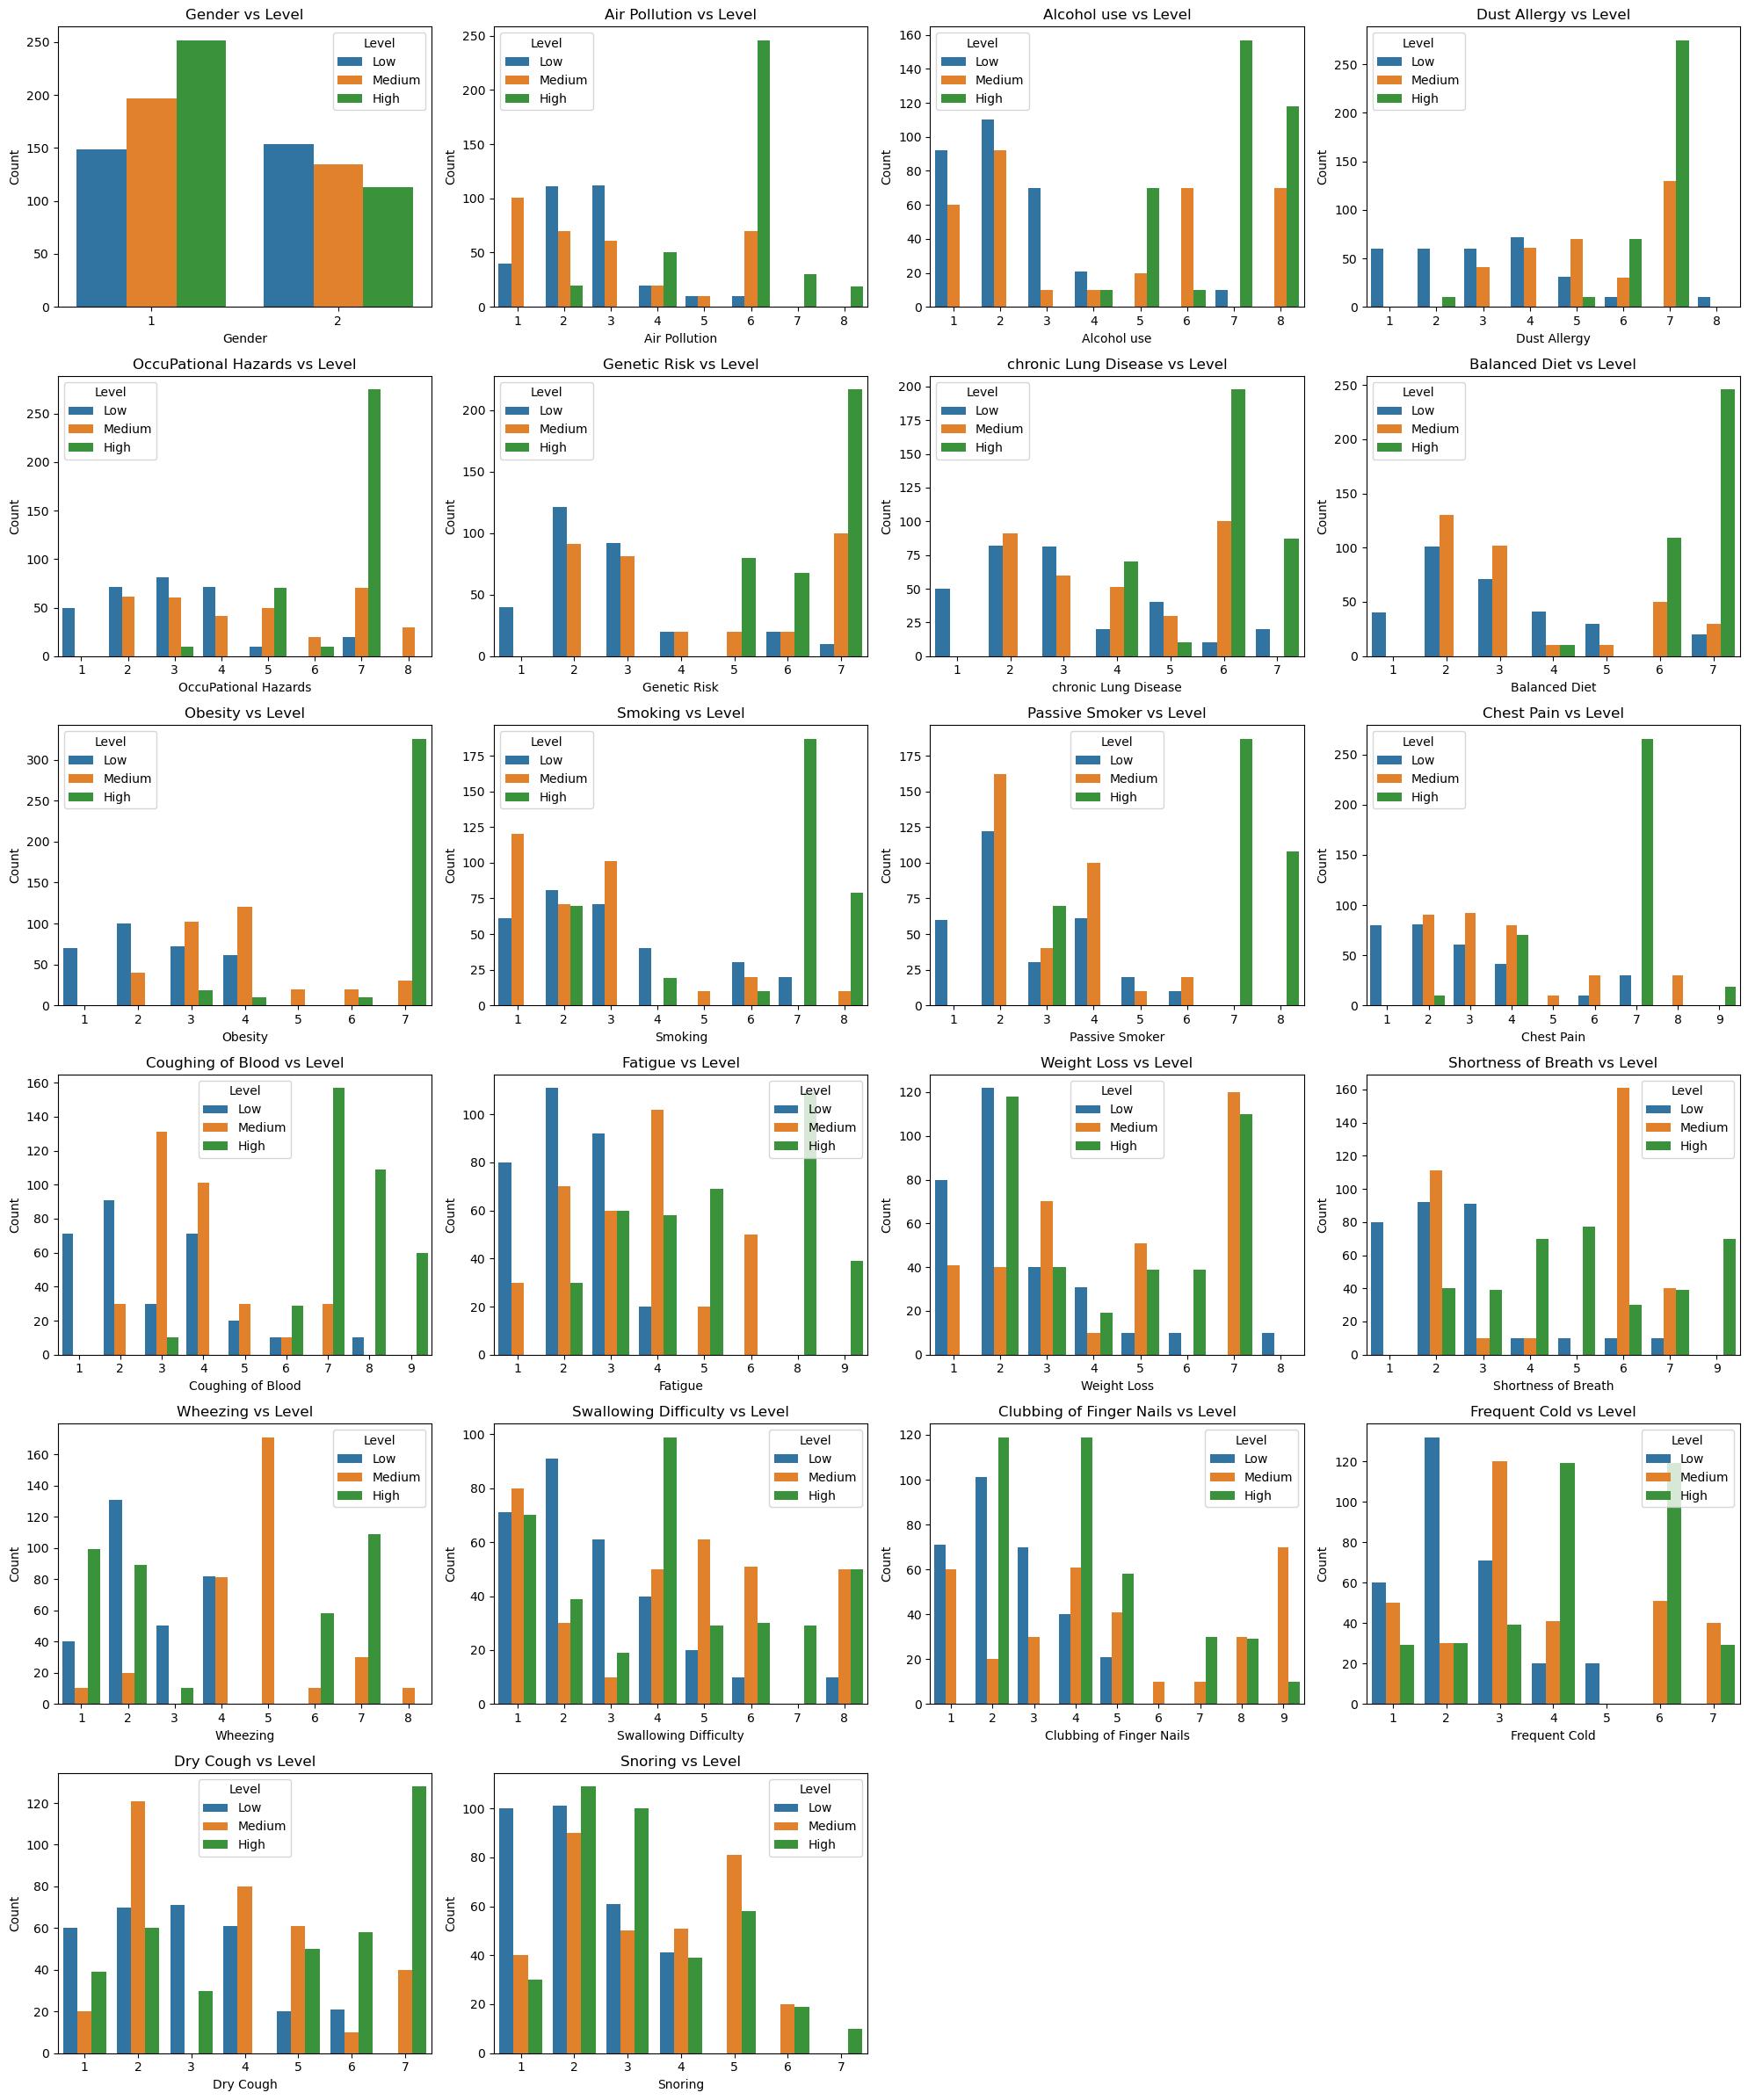

In [64]:
features = df_feature.columns.drop(['Level', 'Age'])
n_features = len(features)

n_cols = 4
n_rows = (n_features + n_cols - 1) // n_cols  # Ceiling division

plt.figure(figsize=(20, n_rows * 4))

for i, feature in enumerate(features):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.countplot(data=data, x=feature, hue='Level')
    plt.title(f'{feature} vs Level')
    plt.xlabel(feature)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()


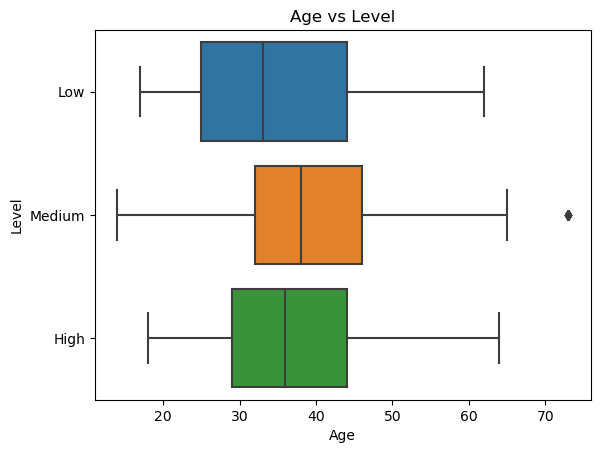

In [68]:
sns.boxplot(data = df_feature, x = 'Age', y = 'Level')
plt.title('Age vs Level')
plt.show()

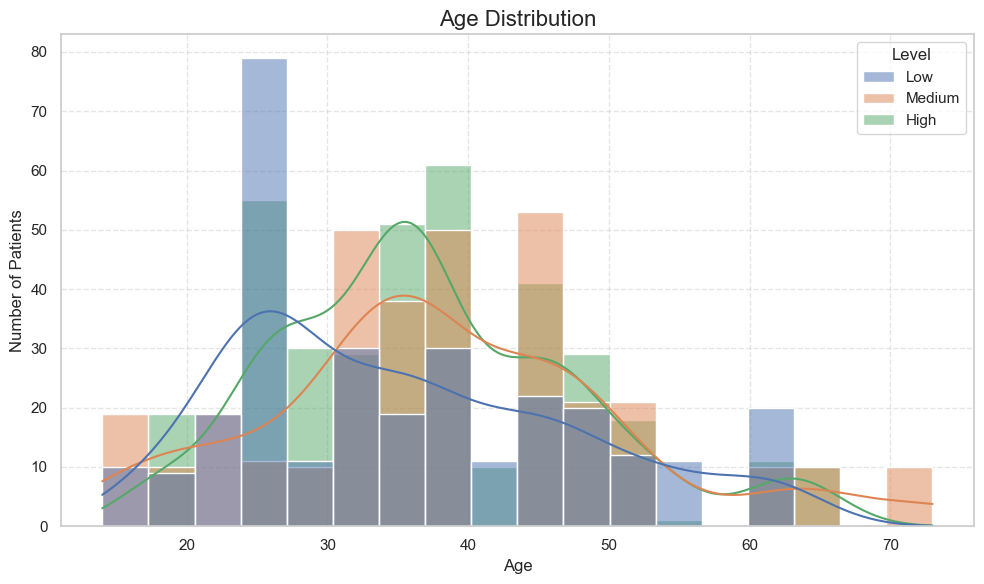

In [74]:
sns.set(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(data = df_feature, x ='Age', hue = 'Level', kde = True)

plt.title('Age Distribution', fontsize=16)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Modelling

### Faktor apa saja yang berkontribusi signifikan terhadap tingkat keparahan kanker paru-paru

In [6]:
from sklearn.feature_selection import chi2
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest

In [55]:
X = df_feature.drop(['Level'], axis=1)
y = df_feature['Level']

chi2_selector = SelectKBest(score_func=chi2, k='all')
chi2_selector.fit(X, y)
chi2_scores = chi2_selector.scores_
chi2_pvalues = chi2_selector.pvalues_

In [56]:
chi2_results = pd.DataFrame({'Feature': X.columns, 
                             'Chi2 Score': chi2_scores,
                             'P-Value': chi2_pvalues})
chi2_results = chi2_results.sort_values(by='Chi2 Score', ascending=False)
print(chi2_results)

                     Feature  Chi2 Score        P-Value
13         Coughing of Blood  818.668884  1.691651e-178
3                Alcohol use  781.909841  1.623436e-170
11            Passive Smoker  752.959791  3.139488e-164
9                    Obesity  712.087562  2.355866e-155
10                   Smoking  671.006253  1.962653e-146
8              Balanced Diet  588.933743  1.302155e-128
12                Chest Pain  524.489521  1.283948e-114
14                   Fatigue  518.900446  2.099906e-113
2              Air Pollution  518.631533  2.402114e-113
6               Genetic Risk  488.649726  7.781445e-107
5       OccuPational Hazards  415.685654   5.432591e-91
4               Dust Allergy  401.040883   8.223917e-88
16       Shortness of Breath  330.880709   1.413081e-72
7       chronic Lung Disease  302.396157   2.165254e-66
19  Clubbing of Finger Nails  257.907679   9.909666e-57
15               Weight Loss  206.666563   1.327169e-45
17                  Wheezing  201.426189   1.823

### Bagaimana faktor-faktor tersebut dapat memprediksi tingkat keparahan kanker paru-paru

In [57]:
from sklearn.model_selection import train_test_split

x = df_feature.drop(['Level'], axis = 1)
y = df_feature['Level']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state = 100)

print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))

700
300
700
300


In [78]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

rf = RandomForestClassifier()
rf.fit(x_train, y_train)
rf_pred = rf.predict(x_test)

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

        High       1.00      1.00      1.00       120
         Low       1.00      1.00      1.00        92
      Medium       1.00      1.00      1.00        88

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



In [80]:
importances = rf.feature_importances_
importance_df = pd.DataFrame({'Feature': x.columns, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)
print(importance_df)

                     Feature  Importance
9                    Obesity    0.098525
11            Passive Smoker    0.094500
13         Coughing of Blood    0.087183
17                  Wheezing    0.079695
3                Alcohol use    0.067373
14                   Fatigue    0.064552
8              Balanced Diet    0.054104
18     Swallowing Difficulty    0.048466
6               Genetic Risk    0.046704
19  Clubbing of Finger Nails    0.042413
16       Shortness of Breath    0.037037
10                   Smoking    0.036381
4               Dust Allergy    0.034891
22                   Snoring    0.034105
12                Chest Pain    0.031397
5       OccuPational Hazards    0.026727
15               Weight Loss    0.025625
2              Air Pollution    0.024033
20             Frequent Cold    0.023539
7       chronic Lung Disease    0.019204
21                 Dry Cough    0.018448
0                        Age    0.004749
1                     Gender    0.000351


In [82]:
log = LogisticRegression(multi_class='multinomial', max_iter=1000)
log.fit(x_train, y_train)
log_pred = log.predict(x_test)

print(classification_report(y_test, log_pred))

              precision    recall  f1-score   support

        High       1.00      1.00      1.00       120
         Low       1.00      1.00      1.00        92
      Medium       1.00      1.00      1.00        88

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



C:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [84]:
dt = DecisionTreeClassifier()
dt.fit(x_train, y_train)
dt_pred = dt.predict(x_test)

print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

        High       1.00      1.00      1.00       120
         Low       1.00      1.00      1.00        92
      Medium       1.00      1.00      1.00        88

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



In [86]:
svm = SVC(kernel='rbf', decision_function_shape='ovo')
svm.fit(x_train, y_train)
svm_pred = svm.predict(x_test)

print(classification_report(y_test, svm_pred))

              precision    recall  f1-score   support

        High       0.97      1.00      0.98       120
         Low       1.00      0.93      0.97        92
      Medium       0.93      0.95      0.94        88

    accuracy                           0.97       300
   macro avg       0.97      0.96      0.96       300
weighted avg       0.97      0.97      0.97       300



In [90]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled, y_train)
knn_pred = knn.predict(x_test_scaled)

print(classification_report(y_test, knn_pred))

              precision    recall  f1-score   support

        High       1.00      1.00      1.00       120
         Low       1.00      1.00      1.00        92
      Medium       1.00      1.00      1.00        88

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300

